# Proyecto: Juegos de Steam - Clustering

### Maestria en Inteligencia Artificial Aplicada UCSM - UTPL

### Curso: Herramientas para Inteligencia Artificial

### Github:
https://github.com/vchirinosb/steam-games

### Plataformas utilizadas:
- Jupyter Lab
- Kaggle

### Librerias utilizadas
- kaggle==2.2.5
- kagglehub==1.0.3
- pandas==3.1.0
- numpy==2.5.4
- scikit-learn==1.9.1
- bokeh==3.10.1
- playwright==1.64.1
- jupyter==1.1.1
- jupyterlab==4.6.5

### Exportación a PDF mediante:
jupyter nbconvert --to pdf steam_games.ipynb


## Descripción del proyecto y origen del dataset

- Steam es la tienda digital de videojuegos para PC mas grande del mundo, con mas de 90 000 juegos publicados.
- Existe un problema de visibilidad, ya que muchos juegos pequeños con buenas reseñas no logran llegar a un público objetivo.
- Valve, empresa propietaria de Steam, necesita identificar los tipos de juegos de su catálogo para mejorar las recomendaciones, secciones destacadas y promociones de la tienda.
- Utilizaremos un dataset de más de 89 000 juegos, actualizado a marzo de 2025, aplicando técnicas de aprendizaje no supervisado para agrupar juegos según sus características.
- El dataset incluye información sobre precios, jugadores, reseñas, recomendaciones y tiempo de juego, entre otras variables.
- Dataset original en Kaggle: https://www.kaggle.com/datasets/artermiloff/steam-games-dataset
- Copia del dataset original, actualizado en carpeta personal de Kaggle: https://www.kaggle.com/datasets/victorhugochirinos/steam-games

## Desarrollo

Para abordar el problema descrito, aplicaremos el método de clustering con el algoritmo **K-Means**, con el fin de agrupar los juegos según sus características.

## Descarga del dataset

`games_march2025_cleaned.csv`, sin juegos duplicados ni versiones de prueba.

In [1]:
!pip install kagglehub

In [2]:
import kagglehub

In [3]:
file_path = kagglehub.dataset_download(
    "victorhugochirinos/steam-games/versions/1",
    path="games_march2025_cleaned.csv"
)

In [4]:
file_path

'/Users/hugo/.cache/kagglehub/datasets/victorhugochirinos/steam-games/versions/1/games_march2025_cleaned.csv'

## Lectura de datos con Pandas

In [5]:
import numpy as np
import pandas as pd

El archivo tiene 47 columnas. Describimos a continuación solo las columnas que vamos a utilizar:

* **name**: Nombre del juego.
* **price**: Precio en dólares (0 = gratis).
* **estimated_owners**: Rango estimado de `owners` del juego, por ejemplo `"20000 - 50000"`.
* **positive** / **negative**: número de reseñas positivas / negativas.
* **recommendations**: Número de usuarios que recomiendan el juego.
* **average_playtime_forever**: Tiempo promedio de juego en minutos.
* **peak_ccu**: Pico de jugadores simultáneos del día anterior a la extracción.
* **achievements**: Número de logros del juego.
* **dlc_count**: Número de contenidos descargables.
* **pct_pos_total**: Porcentaje de reseñas positivas.
* **num_reviews_total**: Número total de reseñas.

In [6]:
columns = [
    "name", "price", "estimated_owners", "positive", "negative", "recommendations",
    "average_playtime_forever", "peak_ccu", "achievements", "dlc_count",
    "pct_pos_total", "num_reviews_total"
]
data = pd.read_csv(file_path, usecols=columns)

In [7]:
data

,name,price,dlc_count,achievements,recommendations,positive,negative,estimated_owners,average_playtime_forever,peak_ccu,pct_pos_total,num_reviews_total
0,Counter-Strike 2,0.00,1,1,4401572,7480813,1135108,100000000 - 200000000,33189,1212356,86,8632939
1,PUBG: BATTLEGROUNDS,0.00,0,37,1732007,1487960,1024436,50000000 - 100000000,0,616738,59,2513842
2,Dota 2,0.00,2,0,14337,1998462,451338,200000000 - 500000000,43031,555977,81,2452595
3,Grand Theft Auto V Legacy,0.00,0,77,1803063,1719950,250012,50000000 - 100000000,19323,117698,87,1803832
4,Tom Clancy's Rainbow Six® Siege,3.99,9,0,1165929,1152763,218446,20000000 - 50000000,14204,89916,84,1168020
...,...,...,...,...,...,...,...,...,...,...,...,...
89613,Outrun Them,3.99,0,6,0,2,0,0 - 20000,0,0,-1,-1
89614,Lands of Pharaoh: Episode 1,10.00,0,0,0,2,0,0 - 20000,0,0,-1,-1
89615,Player One,1.99,0,0,0,2,1,0 - 20000,0,0,-1,-1
89616,DragonRoad,29.99,0,34,0,2,0,0 - 20000,0,0,-1,-1


In [8]:
data.dtypes

name                            str
price                       float64
dlc_count                     int64
achievements                  int64
recommendations               int64
positive                      int64
negative                      int64
estimated_owners                str
average_playtime_forever      int64
peak_ccu                      int64
pct_pos_total                 int64
num_reviews_total             int64
dtype: object

## Preparación de los datos

### Agregar una columna: Número de `owners`

`estimated_owners`: Punto medio del rango del número de `owners`.

In [9]:
def calculate_owners(owners_range):
    low, high = owners_range.split(" - ")
    return (int(low) + int(high)) / 2

In [10]:
data["owners"] = data["estimated_owners"].apply(calculate_owners)

### Filtrar los juegos con datos confiables

Reducimos la data considerando sólo los juegos que tienen tiempo de juego y mayor igual a 50 reseñas.

In [11]:
games = data[(data["average_playtime_forever"] > 0) & (data["num_reviews_total"] >= 50)]
games.shape

(7149, 13)

**Estadísticas del dataset: Cantidad de filas, promedio, mínimo, máximo, promedio, desviación estandar, cuartiles.**

In [12]:
features = [
    "price", "owners", "positive", "negative", "recommendations",
    "average_playtime_forever", "peak_ccu", "achievements", "dlc_count", "pct_pos_total"
]
games[features].describe()

,price,owners,positive,negative,recommendations,average_playtime_forever,peak_ccu,achievements,dlc_count,pct_pos_total
count,7149.000000,7.149000e+03,7.149000e+03,7.149000e+03,7.149000e+03,7.149000e+03,7.149000e+03,7149.000000,7149.000000,7149.000000
mean,12.506427,6.848678e+05,1.008184e+04,1.614599e+03,7.882989e+03,1.381706e+03,8.004840e+02,50.388166,2.567492,79.938733
std,12.503748,5.344798e+06,1.039278e+05,1.717661e+04,6.829198e+04,2.407143e+04,1.840732e+04,261.242010,30.592047,13.760946
min,0.000000,1.000000e+04,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000,0.000000,13.000000
25%,2.990000,3.500000e+04,2.510000e+02,6.100000e+01,1.790000e+02,7.800000e+01,0.000000e+00,7.000000,0.000000,73.000000
50%,9.990000,1.500000e+05,8.180000e+02,1.680000e+02,6.520000e+02,2.340000e+02,4.000000e+00,23.000000,0.000000,83.000000
75%,19.990000,3.500000e+05,3.097000e+03,5.530000e+02,2.600000e+03,5.730000e+02,3.600000e+01,43.000000,1.000000,91.000000
max,69.990000,3.500000e+08,7.480813e+06,1.135108e+06,4.401572e+06,1.462997e+06,1.212356e+06,5000.000000,2004.000000,100.000000


## Histogramas

### Gráficos como imágenes PNG

Al exportar el notebook a PDF, los gráficos interactivos de Bokeh no aparecen porque se dibujan con JavaScript en el navegador. Para que se vean en el PDF, cada gráfico se exporta como imagen PNG usando Playwright (un navegador Chromium sin ventana) y se muestra la imagen en el notebook. Las imágenes también se guardan en la carpeta `images/`.

In [13]:
%pip install playwright

Note: you may need to restart the kernel to use updated packages.


In [14]:
import sys

!{sys.executable} -m playwright install chromium

zsh:1: no such file or directory: /Users/hugo/Documents/UCSM/Maestria/Herramientas


In [15]:
from pathlib import Path

from bokeh.io import export_png, output_notebook
from bokeh.layouts import gridplot
from bokeh.plotting import figure, show
from IPython.display import Image, display

In [16]:
output_notebook()

Loading BokehJS ...

Método `render` muestra un gráfico. Con `INTERACTIVE = False` lo muestra como imagen PNG (visible en el PDF); con `INTERACTIVE = True` lo muestra como gráfico interactivo de Bokeh.

In [17]:
INTERACTIVE = False
IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(exist_ok=True)

def render(chart, name):
    if INTERACTIVE:
        show(chart)
        return
    # The toolbar is useless in a static image
    chart.toolbar_location = None
    # Selenium is also installed, so force the Playwright backend
    file_name = export_png(chart, filename=IMAGES_DIR / f"{name}.png", backend="playwright")
    display(Image(filename=file_name))

Método `histogram` dibuja el histograma de una columna.

In [18]:
def histogram(values, title):
    counts, edges = np.histogram(values, bins=40)
    chart = figure(title=title, width=250, height=200)
    chart.quad(top=counts, bottom=0, left=edges[:-1], right=edges[1:], line_color="white")
    return chart

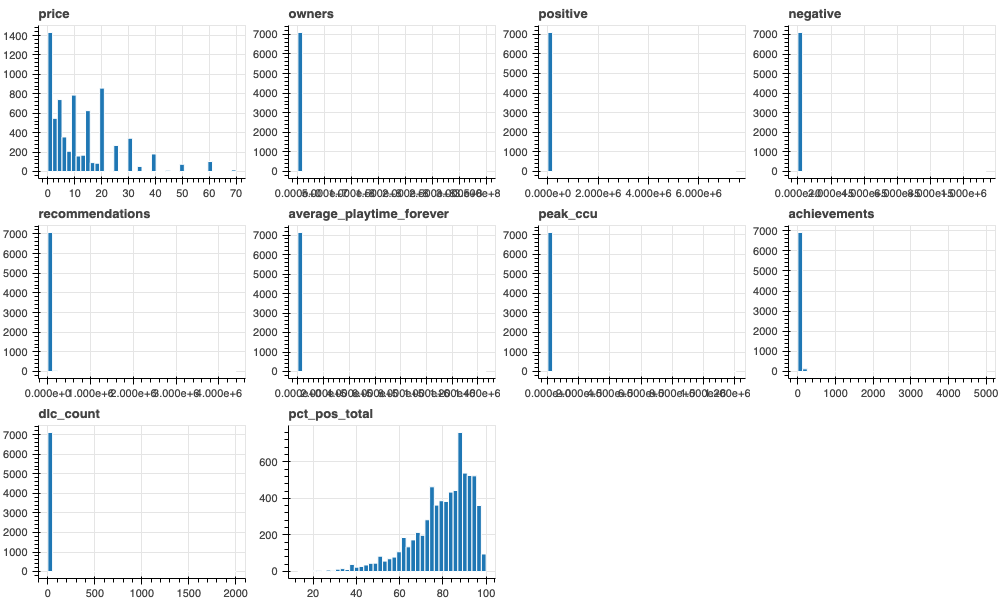

In [19]:
render(gridplot([histogram(games[column], column) for column in features], ncols=4), "histogramas")

### Eliminar outliers

Retiramos los valores imposibles para un jugador real:

* average_playtime_forever > 60 000 minutos: Mas de 1000 horas de promedio por jugador.
* dlc_count > 300: Juegos que venden cientos de DLC (contenido descargable) como paquetes de recursos o canciones.
* achievements > 2000: Juegos hechos para acumular logros.

In [20]:
games = games[
    (games["average_playtime_forever"] <= 60000) &
    (games["dlc_count"] <= 300) &
    (games["achievements"] <= 2000)
].reset_index(drop=True)
games.shape

(7110, 13)

### Escala logarítmica

Para columnas que son conteos: owners, reseñas, minutos, jugadores, logros, DLC (contenido descargable), se aplica `log(1 + x)` para poder comparar juegos pequeños y grandes.

In [21]:
log_columns = [
    "owners", "positive", "negative", "recommendations",
    "average_playtime_forever", "peak_ccu", "achievements", "dlc_count"
]
games_log = games[features].copy()
games_log[log_columns] = np.log1p(games_log[log_columns])

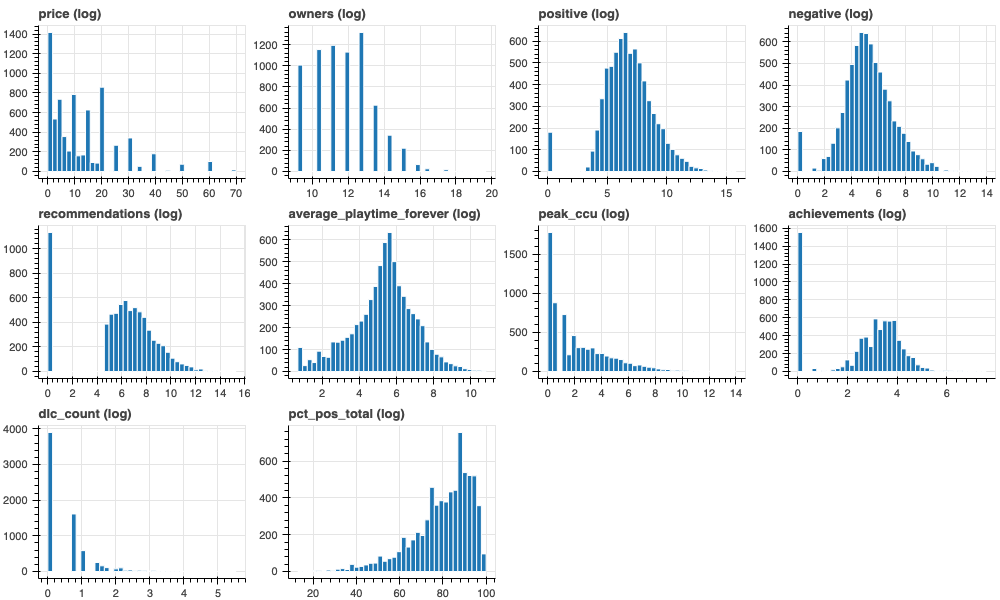

In [22]:
render(gridplot([histogram(games_log[column], column + ' (log)') for column in features], ncols=4), "histogramas_log")

### Estandarizar

Las columnas tienen unidades distintas (dólares, minutos, porcentajes). Se procede a estandarizar la data antes de aplicar K-Means.

In [23]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [24]:
scaler = StandardScaler()
X = scaler.fit_transform(games_log)
X.shape

(7110, 10)

## Número de clusters

Ejecutamos K-Means con k de 1 a 10 y graficamos la inercia. Elegimos k donde la curva se "dobla".

In [25]:
k_values = list(range(1, 11))
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in k_values]

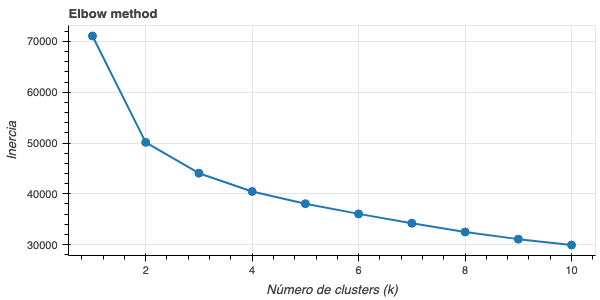

In [26]:
chart = figure(title="Elbow method", width=600, height=300)
chart.line(k_values, inertia, line_width=2)
chart.scatter(k_values, inertia, size=8)
chart.xaxis.axis_label = "Número de clusters (k)"
chart.yaxis.axis_label = "Inercia"
render(chart, "elbow")

Elegimos **k = 3**, debido a que la inercia baja rápido hasta k = 3 y después baja lento.

## K-Means con 3 clusters

In [27]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
games["cluster"] = kmeans.fit_predict(X)

K-Means numera los clusters al azar. Les ponemos nombre según su mediana de reseñas positivas: el de menos reseñas es **NICHE** (nicho), el del medio **MID-TIER** (nivel medio) y el de más reseñas **HIT** (éxito).

In [28]:
order = games.groupby("cluster")["positive"].median().sort_values().index
group_names = dict(zip(order, ["NICHE", "MID-TIER", "HIT"]))
games["group"] = games["cluster"].map(group_names)

**Cantidad de juegos en cada grupo**

In [29]:
groups = ["NICHE", "MID-TIER", "HIT"]
colors = ["#2ca02c", "#1f77b4", "#d62728"]
group_count = games["group"].value_counts().reindex(groups)
group_count

group
NICHE       2736
MID-TIER    3144
HIT         1230
Name: count, dtype: int64

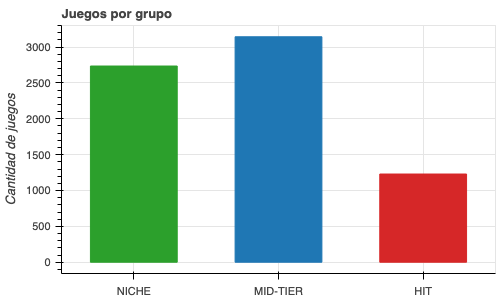

In [30]:
chart = figure(x_range=groups, title="Juegos por grupo", width=500, height=300)
chart.vbar(x=groups, top=group_count.tolist(), width=0.6, color=colors)
chart.yaxis.axis_label = "Cantidad de juegos"
render(chart, "juegos_por_grupo")

## Gráficos de los grupos

Una función dibuja dos columnas con un color por grupo y una estrella en la mediana de cada grupo.

In [31]:
from bokeh.models import ColumnDataSource, HoverTool

In [32]:
def scatter(x_column, y_column, log_scale=True):
    shift = 1 if log_scale else 0
    axis_type = "log" if log_scale else "linear"
    chart = figure(
        title=f"{x_column} vs {y_column}", width=800, height=450,
        x_axis_type=axis_type, y_axis_type=axis_type
    )
    points = []
    for group, color in zip(groups, colors):
        subset = games[games["group"] == group]
        source = ColumnDataSource({
            "x": subset[x_column] + shift,
            "y": subset[y_column] + shift,
            "name": subset["name"]
        })
        points.append(chart.scatter("x", "y", source=source, size=4, alpha=0.4, color=color, legend_label=group))
        # Star on the median of the group
        chart.scatter(
            [subset[x_column].median() + shift], [subset[y_column].median() + shift],
            marker="star", size=30, color=color, line_color="black"
        )
    chart.add_tools(HoverTool(renderers=points, tooltips=[("juego", "@name")]))
    chart.xaxis.axis_label = x_column
    chart.yaxis.axis_label = y_column
    chart.legend.location = "top_left"
    chart.legend.click_policy = "hide"
    render(chart, f"{x_column}_vs_{y_column}")

Gráfico: Reseñas positivas vs reseñas negativas.

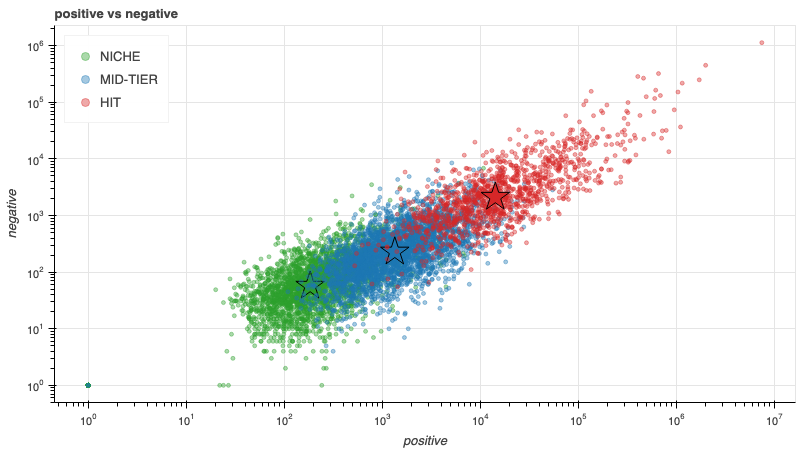

In [33]:
scatter("positive", "negative")

Gráfico: Tiempo promedio de juego vs pico de jugadores simultáneos.

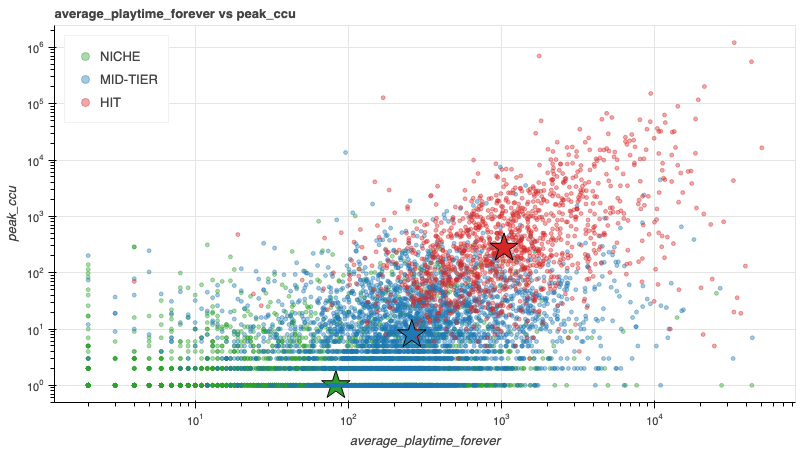

In [34]:
scatter("average_playtime_forever", "peak_ccu")

Gráfico: precio vs porcentaje de reseñas positivas.

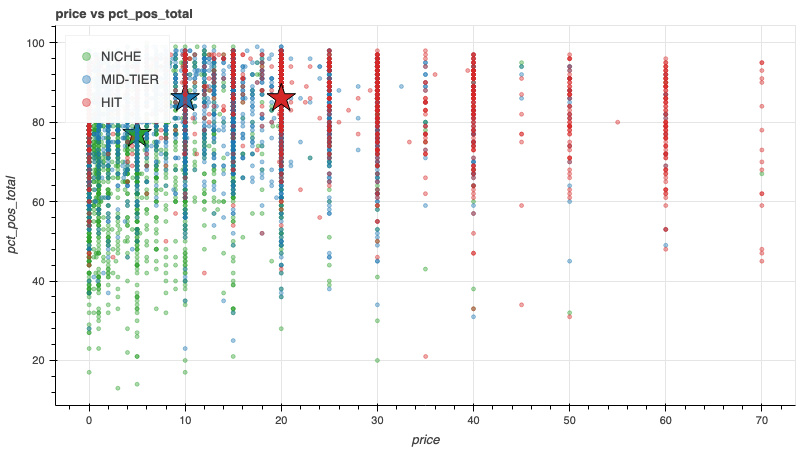

In [35]:
scatter("price", "pct_pos_total", log_scale=False)

## Estadísticas de cada grupo

Estadísticas en base a la mediana.

In [36]:
summary = games.groupby("group")[features].median().reindex(groups)
summary["games"] = group_count
summary

,price,owners,positive,negative,recommendations,average_playtime_forever,peak_ccu,achievements,dlc_count,pct_pos_total,games
group,,,,,,,,,,,
NICHE,4.99,35000.0,183.0,56.0,147.5,82.0,0.0,10.0,0.0,77.0,2736
MID-TIER,9.99,150000.0,1344.0,228.0,1178.5,259.0,7.0,27.0,1.0,86.0,3144
HIT,19.99,750000.0,14266.0,2126.5,11759.5,1040.0,274.5,45.0,2.0,86.0,1230


**Los 10 juegos con más reseñas positivas de cada grupo**

In [37]:
top_games = pd.DataFrame(
    {
        group: games[games["group"] == group].nlargest(10, "positive")["name"].values
        for group in groups
    }
)
top_games

,NICHE,MID-TIER,HIT
0,Last Man Standing,Ultimate Custom Night,Counter-Strike 2
1,Star Fetchers,Emily is Away,Dota 2
2,There Is No Game: Jam Edition 2015,Freddy Fazbear's Pizzeria Simulator,Grand Theft Auto V Legacy
3,Radical Heights,The Room,Tom Clancy's Rainbow Six® Siege
4,the static speaks my name,Milk inside a bag of milk inside a bag of milk,Garry's Mod
5,Meteor 60 Seconds!,The Coffin of Andy and Leyley,Rust
6,Word Game: Episode 0,ABZU,ELDEN RING
7,SUCCUBUS: Prologue,Alien Swarm: Reactive Drop,Stardew Valley
8,Tails Noir: Prologue,The Plan,The Witcher 3: Wild Hunt
9,The Riftbreaker: Prologue,Five Nights at Freddy's 2,Phasmophobia


Según las estadísticas:

- **HIT** (rojo) es el grupo más pequeño: 1230 juegos (17%). Son los grandes éxitos: la mitad tiene 750 000 dueños o más, 14 266 reseñas positivas o más y unas 17 horas de juego promedio (1040 minutos). Su pico de jugadores simultáneos (mediana de 274) muestra que tienen una comunidad que juega todos los días.

- **MID-TIER** (azul) es el grupo más grande: 3144 juegos (44%). Son juegos con un público establecido: mediana de 150 000 dueños, 1344 reseñas positivas y unas 4 horas de juego.

- **NICHE** (verde) tiene 2736 juegos (38%). Son juegos pequeños y baratos: 35 000 dueños, 183 reseñas positivas, menos de 1.5 horas de juego y, en la mayoría, ningún jugador simultáneo.

## Clasificar un juego nuevo

Aplicamos al juego nuevo la misma transformación (logaritmo y estandarización) y le pedimos a K-Means el grupo más cercano.

In [38]:
def classify_game(game):
    new_game = pd.DataFrame([game])[features]
    new_game[log_columns] = np.log1p(new_game[log_columns])
    cluster = kmeans.predict(scaler.transform(new_game))[0]
    return group_names[cluster]

In [39]:
# NICHE
classify_game(
    {
        "price": 4.99, "owners": 10000, "positive": 120, "negative": 30, "recommendations": 100,
        "average_playtime_forever": 90, "peak_ccu": 1, "achievements": 12, "dlc_count": 0, "pct_pos_total": 80
    }
)

'NICHE'

In [40]:
# MID-TIER
classify_game(
    {
        "price": 14.99, "owners": 150000, "positive": 2500, "negative": 300, "recommendations": 2000,
        "average_playtime_forever": 400, "peak_ccu": 30, "achievements": 35, "dlc_count": 1, "pct_pos_total": 89
    }
)

'MID-TIER'

In [41]:
# HIT
classify_game(
    {
        "price": 39.99, "owners": 3500000, "positive": 90000, "negative": 9000, "recommendations": 80000,
        "average_playtime_forever": 2500, "peak_ccu": 9000, "achievements": 60, "dlc_count": 8, "pct_pos_total": 91
    }
)

'HIT'

## Conclusiones

- Con K-Means se agruparon 7110 juegos de Steam en tres grupos según su desempeño en la tienda: **HIT**, **MID-TIER** y **NICHE**.
- Con los grupos definidos, cualquier juego nuevo se puede clasificar a partir de sus estadísticas.
- Para los outliers se revisaron los histogramas y solo se quitaron los valores imposibles. Los juegos más grandes se mantuvieron porque forman el grupo de los éxitos, y se aplicó logaritmo para reducir el sesgo de los datos.